# Online Store Sales & Customer Analysis

**Practice portfolio project | Python • pandas • matplotlib**

**Question:** If I was helping a small online store, what could I learn from its sales records?

I check the data first, then look at monthly revenue, product categories, regions and returning customers. At the end, I share three suggestions the store owner could explore.

The data comes from a **synthetic retail practice workbook**. These are not real customer orders, and the results are not claims about a real business. The original workbook included online, store and distributor orders. This project focuses on the **Online** channel only.

## 1. Load the files

There are three simple files: orders, products and customers. Run the notebook from the repository folder. All dates are saved in the CSV format `YYYY-MM-DD`.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works whether the notebook is run from the repo root or notebooks/ folder.
root = Path.cwd()
if not (root / 'data').exists():
    root = root.parent

data_dir = root / 'data'
charts_dir = root / 'charts'
outputs_dir = root / 'outputs'
charts_dir.mkdir(exist_ok=True)
outputs_dir.mkdir(exist_ok=True)

orders = pd.read_csv(data_dir / 'orders.csv')
products = pd.read_csv(data_dir / 'products.csv')
customers = pd.read_csv(data_dir / 'customers.csv')

print('Orders:', len(orders), '| Products:', len(products), '| Customers:', len(customers))
display(orders.head(3))

Orders: 612 | Products: 30 | Customers: 150


,Order_ID,Order_Date,Ship_Date,Customer_ID,Product_ID,Region,Sales_Channel,Quantity,Unit_Price,Discount,Revenue,Cost,Profit,Returned,Salesperson
0,O00001,2025-02-18,2025-02-27,C0085,P020,North,Distributor,2,33.75,0.00,67.50,47.86,19.64,No,Nour
1,O00002,2025-03-18,2025-03-22,C0101,P015,north,Store,2,43.32,0.00,86.64,65.22,21.42,No,Amina
2,O00003,2025-09-03,2025-09-04,C0003,P022,south,Store,4,76.38,0.05,290.24,163.52,126.72,No,Amina


## 2. Check the data

Before making charts I look for duplicate rows, missing customer IDs, missing discounts and non-positive quantities. Missing customer IDs are important: those sales still count toward store revenue, but cannot be included in customer-level analysis.

In [2]:
issues = pd.DataFrame({
    'Check': [
        'Exact duplicate order rows',
        'Missing customer IDs',
        'Missing discount values',
        'Non-positive quantities',
        'Orders marked returned'
    ],
    'Rows': [
        orders.duplicated().sum(),
        orders['Customer_ID'].isna().sum(),
        orders['Discount'].isna().sum(),
        (orders['Quantity'] <= 0).sum(),
        orders['Returned'].astype(str).str.strip().str.lower().eq('yes').sum()
    ]
})
display(issues)

,Check,Rows
0,Exact duplicate order rows,12
1,Missing customer IDs,8
2,Missing discount values,10
3,Non-positive quantities,4
4,Orders marked returned,55


## 3. Clean the orders and select online sales

I remove only **exact** duplicates, make text labels consistent, and exclude flagged returns and invalid sales from revenue analysis. I keep the source `Revenue` values rather than guessing missing discounts. The `Returned` flag is treated as a full-return indicator for this practice analysis; real client work would need a returns/refunds reconciliation.

In [3]:
cleaned = orders.drop_duplicates().copy()
for column in ['Region', 'Sales_Channel', 'Returned']:
    cleaned[column] = cleaned[column].astype('string').str.strip().str.title()

cleaned['Order_Date'] = pd.to_datetime(cleaned['Order_Date'], errors='coerce')
cleaned['Ship_Date'] = pd.to_datetime(cleaned['Ship_Date'], errors='coerce')

online = cleaned.loc[cleaned['Sales_Channel'].eq('Online')].copy()
online_sales = online.loc[
    online['Returned'].eq('No')
    & online['Order_Date'].notna()
    & (online['Quantity'] > 0)
    & (online['Unit_Price'] > 0)
    & (online['Revenue'] > 0)
].copy()

online_sales = online_sales.merge(
    products[['Product_ID', 'Category', 'Product_Name']],
    on='Product_ID', how='left', validate='many_to_one'
)

print('Rows in full dataset:', len(orders))
print('Rows after removing exact duplicates:', len(cleaned))
print('Online channel rows:', len(online))
print('Online sales included in analysis:', len(online_sales))
print('Unmatched products:', online_sales['Category'].isna().sum())

Rows in full dataset: 612
Rows after removing exact duplicates: 600
Online channel rows: 196
Online sales included in analysis: 175
Unmatched products: 0


## 4. Key numbers

These figures describe **non-returned, valid online sales in the practice data**. They are not audited net revenue. The dataset does not specify a currency, so amounts below are shown in *dataset units*.

In [4]:
total_revenue = online_sales['Revenue'].sum()
order_count = online_sales['Order_ID'].nunique()
average_order = total_revenue / order_count
known_customers = online_sales['Customer_ID'].nunique()

kpis = pd.DataFrame({
    'Metric': ['Online sales revenue', 'Online orders', 'Average order value', 'Identified customers'],
    'Value': [f'{total_revenue:,.2f}', f'{order_count:,}', f'{average_order:,.2f}', f'{known_customers:,}']
})
display(kpis)

,Metric,Value
0,Online sales revenue,"126,657.37"
1,Online orders,175
2,Average order value,723.76
3,Identified customers,106


## 5. Monthly sales trend

This shows which months were stronger or weaker in the practice data. One high month does not prove that seasonality will repeat.

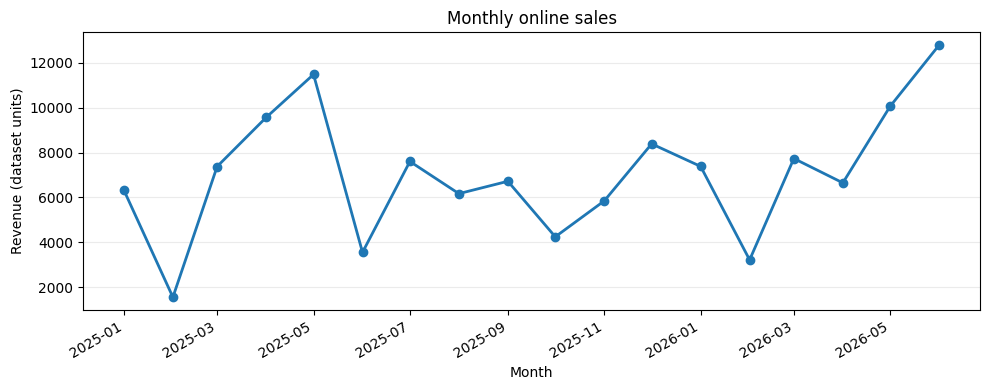

In [5]:
monthly = (
    online_sales.groupby(pd.Grouper(key='Order_Date', freq='MS'))['Revenue']
    .sum().asfreq('MS', fill_value=0)
)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index, monthly.values, marker='o', linewidth=2)
ax.set(title='Monthly online sales', xlabel='Month', ylabel='Revenue (dataset units)')
ax.grid(axis='y', alpha=0.25)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(charts_dir / '01_monthly_sales.png', dpi=180)
plt.show()

## 6. Which products and regions bring in sales?

I join the orders with the product table to calculate revenue by category. I also compare sales by region. These numbers help decide what to investigate; they do not explain *why* people bought a product.

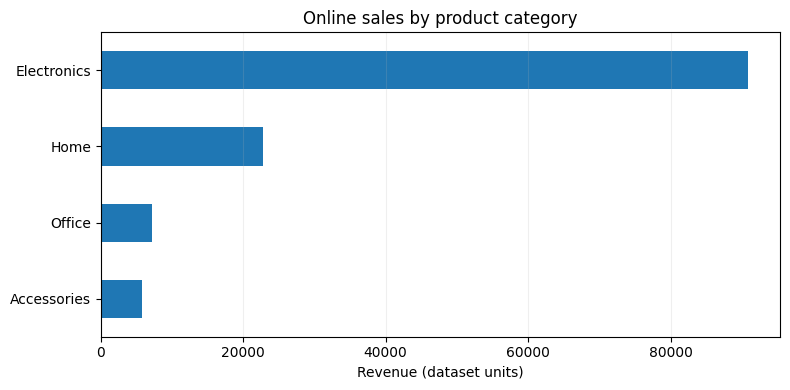

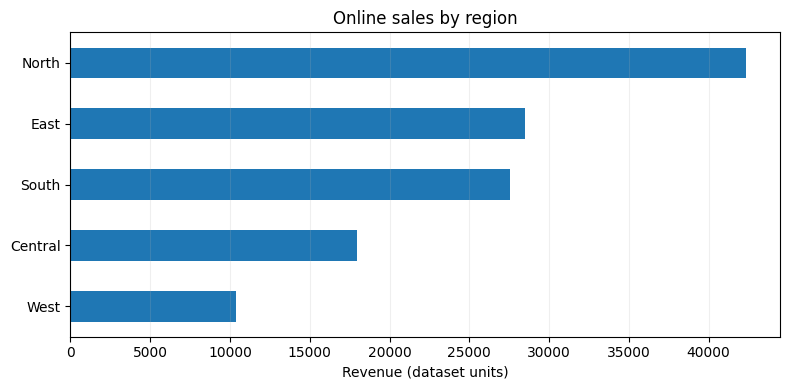

In [6]:
category_sales = online_sales.groupby('Category')['Revenue'].sum().sort_values(ascending=False)
region_sales = online_sales.groupby('Region')['Revenue'].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
category_sales.sort_values().plot(kind='barh', ax=ax)
ax.set(title='Online sales by product category', xlabel='Revenue (dataset units)', ylabel='')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
fig.savefig(charts_dir / '02_category_sales.png', dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
region_sales.sort_values().plot(kind='barh', ax=ax)
ax.set(title='Online sales by region', xlabel='Revenue (dataset units)', ylabel='')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
fig.savefig(charts_dir / '03_region_sales.png', dpi=180)
plt.show()

## 7. One-time vs repeat customers

I group **identified** customers by number of orders. I call someone a repeat customer if they have at least 2 orders. I make a separate “Top repeat” group for repeat customers in the top 25% of repeat-customer spending. This is a basic rule for a first client report, not a machine-learning prediction.

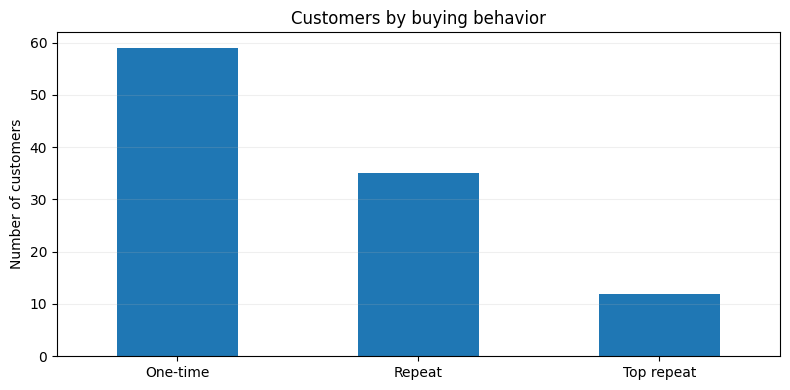

,Customer_ID,Orders,Total_Spent,Last_Order,Days_Since_Last_Order,Group
76,C0107,3,4638.89,2026-01-28,152,Top repeat
37,C0049,3,4503.71,2026-03-10,111,Top repeat
10,C0015,3,4268.71,2026-06-19,10,Top repeat
75,C0106,4,4253.52,2026-06-25,4,Top repeat
5,C0008,2,4189.77,2025-04-05,450,Top repeat
99,C0142,1,3843.60,2025-05-07,418,One-time
47,C0061,2,3579.38,2026-05-21,39,Top repeat
35,C0045,2,3559.67,2025-12-15,196,Top repeat


In [7]:
customer_summary = (
    online_sales.dropna(subset=['Customer_ID'])
    .groupby('Customer_ID')
    .agg(Orders=('Order_ID', 'nunique'), Total_Spent=('Revenue', 'sum'), Last_Order=('Order_Date', 'max'))
    .reset_index()
)
customer_summary['Days_Since_Last_Order'] = (
    online_sales['Order_Date'].max() - customer_summary['Last_Order']
).dt.days

repeat_spend = customer_summary.loc[customer_summary['Orders'] >= 2, 'Total_Spent']
top_threshold = repeat_spend.quantile(0.75) if len(repeat_spend) else float('inf')

def customer_group(row):
    if row['Orders'] == 1:
        return 'One-time'
    if row['Total_Spent'] >= top_threshold:
        return 'Top repeat'
    return 'Repeat'

customer_summary['Group'] = customer_summary.apply(customer_group, axis=1)
segment_counts = customer_summary['Group'].value_counts().reindex(
    ['One-time', 'Repeat', 'Top repeat'], fill_value=0
)

fig, ax = plt.subplots(figsize=(8, 4))
segment_counts.plot(kind='bar', rot=0, ax=ax)
ax.set(title='Customers by buying behavior', xlabel='', ylabel='Number of customers')
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig(charts_dir / '04_customer_groups.png', dpi=180)
plt.show()

display(customer_summary.sort_values('Total_Spent', ascending=False).head(8))

## 8. Save the files

I export the cleaned online sales, the customer groups and a small summary so another person can check the results. The cleaned Excel workbook and the short PDF are also included in the GitHub project as examples of client-style deliverables.

In [8]:
import json

online_sales.to_csv(outputs_dir / 'clean_online_sales.csv', index=False)
customer_summary.to_csv(outputs_dir / 'customer_groups.csv', index=False)

results = {
    'data_type': 'synthetic practice dataset',
    'original_order_rows': int(len(orders)),
    'exact_duplicates': int(orders.duplicated().sum()),
    'online_channel_rows_after_dedup': int(len(online)),
    'valid_nonreturned_online_sales': int(len(online_sales)),
    'sales_revenue_data_units': round(float(total_revenue), 2),
    'online_orders': int(order_count),
    'average_order_value_data_units': round(float(average_order), 2),
    'identified_customers': int(known_customers),
    'online_rows_missing_customer_id': int(online_sales['Customer_ID'].isna().sum()),
    'largest_product_category': str(category_sales.index[0]),
    'largest_category_share_pct': round(float(category_sales.iloc[0]/total_revenue*100), 1),
    'strongest_revenue_month': str(monthly.idxmax().strftime('%Y-%m')),
    'customer_groups': {k:int(v) for k,v in segment_counts.items()}
}
(outputs_dir / 'analysis_summary.json').write_text(json.dumps(results, indent=2), encoding='utf-8')
print('Saved CSV files and analysis_summary.json')
print(json.dumps(results, indent=2))

Saved CSV files and analysis_summary.json
{
  "data_type": "synthetic practice dataset",
  "original_order_rows": 612,
  "exact_duplicates": 12,
  "online_channel_rows_after_dedup": 196,
  "valid_nonreturned_online_sales": 175,
  "sales_revenue_data_units": 126657.37,
  "online_orders": 175,
  "average_order_value_data_units": 723.76,
  "identified_customers": 106,
  "online_rows_missing_customer_id": 2,
  "largest_product_category": "Electronics",
  "largest_category_share_pct": 71.7,
  "strongest_revenue_month": "2026-06",
  "customer_groups": {
    "One-time": 59,
    "Repeat": 35,
    "Top repeat": 12
  }
}


## 9. What I would tell the store owner

The goal is not just making charts; it is deciding what to look at next.

1. **Review best-selling categories.** Check stock availability and margins for the category with the highest online revenue. Revenue alone does not mean the product is the most profitable.
2. **Give one-time customers a reason to return.** Try a small follow-up offer or email campaign, then measure if repeat purchases improve. I would ask about marketing permissions first.
3. **Investigate weak months.** Compare traffic, promotions and stock problems before changing the marketing budget. Historical revenue alone cannot explain the drop.

**Limits:** This uses synthetic data. Missing customer IDs are excluded only from customer analysis, flagged returns are left out of sales revenue, and the source does not define currency or a full refunds ledger.